# Off-ball runs & space creation — match walkthrough

**Brisbane Roar FC v Adelaide United, 23 November 2024** · SkillCorner match `1874553` · frames `5000–5999` (a 100-second window of one match).

This walkthrough is a reproducible scouting *triage*, not a causal estimate or a match-wide player ranking. We use official broadcast tracking, explicitly check known possession and inspect a candidate in context. The first run downloads the complete ~91 MB tracking file, even though this example parses only a window.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import matplotlib.pyplot as plt
import pandas as pd
from src.data_loader import load_match
from src.kinematics import add_kinematics, segment_runs
from src.run_detector import detect_and_value_runs
from src.spatial_model import pitch_control
from src.visualize import plot_frame, animate_tracking
pd.set_option("display.max_columns", 30)

## 1. Load and inspect coverage

SkillCorner coordinates are centred on the pitch in metres, with timestamps in seconds. `is_detected=False` means a provider-extrapolated position; missing player records and long camera gaps are not fabricated. Data are cached locally in `data/` and are not redistributed in this repository.

In [2]:
raw, metadata = load_match(1874553, cache_dir=ROOT / "data", start_frame=5000, end_frame=5999)
length, width = metadata["pitch_length"], metadata["pitch_width"]
frames = raw.drop_duplicates(["period", "frame"])
print(f"{metadata['home_team']['name']} vs {metadata['away_team']['name']}")
print(f"Player observations: {len(raw):,}; available frames: {len(frames):,}; "
      f"detected fraction: {raw.is_detected.mean():.1%}; "
      f"known possession player: {frames.possession_player_id.notna().mean():.1%}")
raw.head(3)

Brisbane Roar FC vs Adelaide United Football Club
Player observations: 22,000; available frames: 1,000; detected fraction: 70.3%; known possession player: 46.6%


,frame,period,timestamp,player_id,x,y,team_id,team,is_detected,ball_x,ball_y,ball_is_detected,possession_team,possession_player_id
0,5000,1,499.0,50999,-38.89,-3.97,1802,home,False,-1.47,-30.13,True,away,NaN
1,5000,1,499.0,69111,-14.11,-19.81,1802,home,True,-1.47,-30.13,True,away,NaN
2,5000,1,499.0,51050,-16.89,-0.45,1802,home,True,-1.47,-30.13,True,away,NaN


## 2. Kinematics and eligibility

We fill only bounded gaps of at most 5 frames, smooth x/y with a 7-sample Savitzky–Golay filter, and differentiate against the actual timestamps. A run is a sustained bout ≥4 m/s for ≥0.7 seconds; these are tunable illustrative thresholds. Provider-extrapolated positions remain in the analysis. A run qualifies only when its player is not the known ball carrier for the entire bout and their team has uninterrupted known possession. Strict filtering can exclude many genuine runs. For this window we require at least seven tracked players per team and at least 20% directly detected at both endpoints; this deliberately permissive setting relies heavily on extrapolation and should be stress-tested.

In [3]:
tracking = add_kinematics(raw)
bouts = segment_runs(tracking)
# home_team_side is specified per half, as a direction of play.
directions = {}
for period, side in enumerate(metadata["home_team_side"], start=1):
    home_direction = {"left_to_right": 1, "right_to_left": -1}[side]
    directions[period, "home"] = home_direction
    directions[period, "away"] = -home_direction
runs = detect_and_value_runs(tracking, directions, pitch_length=length, pitch_width=width, min_detected_fraction=0.2)
print(f"Speed bouts: {len(bouts)}; eligible valued off-ball bouts: {len(runs)}")
cols = ["player_id", "team", "start_frame", "end_frame", "run_type", "duration_s", "peak_speed_mps", "space_created_m2", "xt_added_proxy"]
runs.sort_values("xt_added_proxy", ascending=False)[cols].round(4)

Speed bouts: 69; eligible valued off-ball bouts: 6


,player_id,team,start_frame,end_frame,run_type,duration_s,peak_speed_mps,space_created_m2,xt_added_proxy
4,50966,home,5423,5469,run in behind,4.6,6.2310,1145.9068,0.0060
3,51002,home,5427,5467,run in behind,4.0,5.2194,1031.7904,0.0054
5,795537,home,5436,5468,run in behind,3.2,4.6775,821.2353,0.0046
0,50994,home,5442,5468,other forward run,2.6,4.4440,648.1592,0.0039
1,287934,home,5436,5459,other forward run,2.3,4.2377,638.5631,0.0032
2,287934,home,5493,5519,defender-follow candidate,2.6,5.2504,-68.0050,-0.0010


## 3. Inspect a candidate

The model ranks change in **team-wide** xT-weighted control during the run. It does not establish that the runner caused it; the ball, teammates, defenders, and camera coverage also change. Concurrent runs can share the same spatial gain and must not be summed as independent player contributions. The line on the pitch traces the selected runner; blue is home, amber is away.

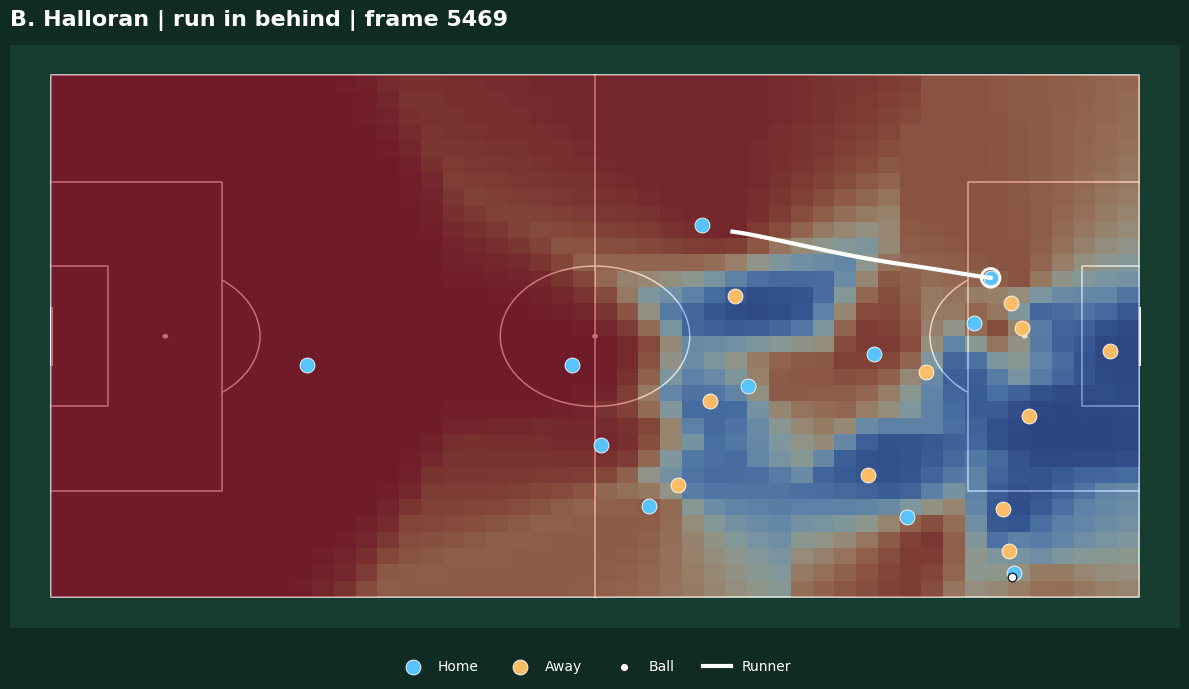

Candidate: B. Halloran, home; 4.6 s, peak 6.2 m/s
Observed team control change: +1145.9 m²; normalized xT-weighted change: +0.00597


In [4]:
if runs.empty:
    raise RuntimeError("No qualifying runs in this window; try a different frame window or inspect coverage.")
selected = runs.sort_values("xt_added_proxy", ascending=False).iloc[0]
period, end = int(selected.period), int(selected.end_frame)
snapshot = tracking[(tracking.period == period) & (tracking.frame == end)].dropna(subset=["x_smooth", "y_smooth", "team"])
attack = snapshot[snapshot.team == selected.team]
defend = snapshot[snapshot.team != selected.team]
surface = pitch_control(attack[["x_smooth", "y_smooth"]].to_numpy(), defend[["x_smooth", "y_smooth"]].to_numpy(),
                        attack[["vx", "vy"]].fillna(0).to_numpy(), defend[["vx", "vy"]].fillna(0).to_numpy(),
                        pitch_length=length, pitch_width=width)
trajectory = tracking[(tracking.period == period) & (tracking.player_id == selected.player_id) &
                      tracking.frame.between(selected.start_frame, selected.end_frame)]
name_lookup = {p["id"]: p.get("short_name", str(p["id"])) for p in metadata["players"]}
name = name_lookup.get(selected.player_id, str(selected.player_id))
fig, ax = plot_frame(snapshot, pitch_length=length, pitch_width=width, control=surface,
                     trajectory=trajectory, title=f"{name} | {selected.run_type} | frame {end}")
(ROOT / "figures").mkdir(exist_ok=True)
fig.savefig(ROOT / "figures" / "run_freeze_frame.png", dpi=150, facecolor=fig.get_facecolor())
plt.show()
print(f"Candidate: {name}, {selected.team}; {selected.duration_s:.1f} s, peak {selected.peak_speed_mps:.1f} m/s")
print(f"Observed team control change: {selected.space_created_m2:+.1f} m²; normalized xT-weighted change: {selected.xt_added_proxy:+.5f}")

The background is an uncalibrated time-to-intercept control score: red favours the selected team; blue favours the opposition. The run labels are geometric candidates, not verified tactical intentions. Coach review should check whether defenders actually followed the runner, the ball was playable, and another run explains the same change.

In [5]:
clip = tracking[(tracking.period == period) & tracking.frame.between(int(selected.start_frame), int(selected.end_frame))]
gif = animate_tracking(clip, ROOT / "figures" / "run_clip.gif", pitch_length=length, pitch_width=width,
                       step=2, title=f"{name}: candidate run")
print(f"Saved {gif.relative_to(ROOT)}")

Saved figures/run_clip.gif


## 4. What to test next

1. Video-code a stratified sample of candidates, measure precision/recall by run type and report disagreements.
2. Evaluate coverage and threshold sensitivity; compare results with and without provider-extrapolated positions.
3. Use a matched counterfactual or a learned defender-response model to isolate the run's contribution; include pass feasibility and ball travel time.
4. Validate the xT and control models out of sample for this competition before making player comparisons.